# 06 - Expected Loss (Perdita Attesa)

**Progetto:** Credit Risk Scorecard - *Give Me Some Credit*

Calcoliamo la Perdita Attesa (Expected Loss) per ciascun cliente con la formula standard del risk
management bancario:

$$EL = PD \times LGD \times EAD$$

dove **PD** (Probability of Default) è la probabilità di insolvenza già stimata dal modello
XGBoost (notebook 04/05), **LGD** (Loss Given Default) è la quota della esposizione che si stima
di perdere in caso di default, ed **EAD** (Exposure at Default) è l'esposizione — l'importo a
rischio al momento del default.

**Avvertenza metodologica, da tenere bene a mente in tutto il notebook:** a differenza di un
dataset bancario interno reale, *Give Me Some Credit* **non contiene una colonna con il limite di
credito, l'importo del prestito o il saldo residuo**. LGD ed EAD quindi non sono osservabili nei
dati: li costruiamo con assunzioni ragionevoli, dichiarate esplicitamente e discusse criticamente,
non calcolati. Questo notebook è un **esercizio illustrativo del framework PD/LGD/EAD**, utile per
dimostrare comprensione del metodo — i valori assoluti di perdita attesa non vanno interpretati come
una stima accurata di un portafoglio reale (si veda la sezione Limiti in fondo).

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 120)

COLOR_SEQ = '#2a78d6'
COLOR_CRITICAL = '#d03b3b'
COLOR_GOOD = '#0ca30c'
GRID_COLOR = '#e1e0d9'
TEXT_COLOR = '#0b0b0b'
MUTED_COLOR = '#898781'

plt.rcParams.update({
    'figure.facecolor': '#fcfcfb',
    'axes.facecolor': '#fcfcfb',
    'axes.edgecolor': GRID_COLOR,
    'axes.grid': True,
    'grid.color': GRID_COLOR,
    'grid.linewidth': 0.8,
    'axes.axisbelow': True,
    'text.color': TEXT_COLOR,
    'axes.labelcolor': TEXT_COLOR,
    'xtick.color': MUTED_COLOR,
    'ytick.color': MUTED_COLOR,
    'font.size': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

## 1. Caricamento dataset pulito e PD stimata

Uniamo il dataset pulito (per `RevolvingUtilizationOfUnsecuredLines`, usata nel proxy di EAD) con
le probabilità di default stimate dal modello XGBoost, salvate nel notebook 04.

*Nota sulla valuta:* il dataset non indica la valuta degli importi. Trattandosi di una fonte
statunitense, in tutto il progetto assumiamo dollari USA ($): reddito, EAD ed Expected Loss.

In [2]:
PROJECT_ROOT = Path.cwd().resolve().parents[1]
CLEAN_PATH = PROJECT_ROOT / 'data' / 'processed' / 'cs-training-clean.csv'
PD_PATH = PROJECT_ROOT / 'data' / 'processed' / 'probabilita_insolvenza.csv'

df = pd.read_csv(CLEAN_PATH, index_col=0)
pd_scores = pd.read_csv(PD_PATH).set_index('CustomerID')

assert set(df.index) == set(pd_scores.index), "Gli id non combaciano tra i due file"

data = df.join(pd_scores[['PD']], how='inner')
print(f"Righe unite: {len(data):,}")
print(f"PD media: {data['PD'].mean():.4f}  |  tasso di default osservato: {data['SeriousDlqin2yrs'].mean():.4f}")

Righe unite: 149,999
PD media: 0.0669  |  tasso di default osservato: 0.0668


## 2. Proxy di EAD (Exposure at Default)

Il dataset offre due strade indicate, nessuna delle due un dato osservato direttamente:

- **(a)** `RevolvingUtilizationOfUnsecuredLines × limite di fido assunto` (es. 25.000 $)
- **(b)** `MonthlyIncome × DebtRatio` come proxy dell'esposizione debitoria complessiva

Verifichiamo entrambe prima di scegliere, invece di assumere quale sia la migliore.

In [3]:
proxy_b = data['MonthlyIncome'] * data['DebtRatio']
print("Opzione (b): MonthlyIncome x DebtRatio")
print(proxy_b.describe())
print(f"Percentuale di righe con esposizione implicita > 1.000.000: {(proxy_b > 1_000_000).mean() * 100:.1f}%")
print(f"Valore massimo: {proxy_b.max():,.0f}")

Opzione (b): MonthlyIncome x DebtRatio
count    1.499990e+05
mean     1.708379e+06
std      5.168551e+06
min      0.000000e+00
25%      7.768787e+02
50%      2.106724e+03
75%      4.795432e+03
max      3.111925e+07
dtype: float64
Percentuale di righe con esposizione implicita > 1.000.000: 14.3%
Valore massimo: 31,119,250


**L'opzione (b) non è utilizzabile così com'è.** `DebtRatio` è definito come rapporto tra rata
debitoria mensile e reddito mensile: moltiplicarlo per `MonthlyIncome` non restituisce
un'esposizione (uno *stock*, un saldo), ma una stima di rata mensile complessiva (un *flusso*) — una
grandezza concettualmente diversa da "importo a rischio in caso di default". A questo si aggiunge
un problema numerico concreto, già discusso nel notebook `01_eda`: `DebtRatio` ha una coda estrema
legata a redditi mancanti o vicini a zero, e anche dopo il winsorizing resta fino a ~4.979. Il
risultato: il 14,3% delle righe implicherebbe un'esposizione superiore a 1 milione, con un massimo
di oltre 31 milioni — chiaramente non sensato per credito al consumo.

**Scegliamo l'opzione (a)**: `RevolvingUtilizationOfUnsecuredLines` è già una misura di utilizzo di
un fido *revolving non garantito* — esattamente il tipo di esposizione che EAD deve rappresentare —
ed è stata winsorizzata nel notebook `01_eda` (max ≈ 1,093), quindi l'esposizione risultante resta
in un intervallo economicamente sensato. Assumiamo un **limite di fido standard di 25.000 $** per
tutti i clienti (assunzione dichiarata, non un dato osservato — un valore ragionevole per credito al
consumo non garantito, ma nella realtà varierebbe per cliente in base a reddito e storia
creditizia).

In [4]:
EAD_LIMIT_ASSUMPTION = 25_000  # assunzione: limite di fido standard per tutti i clienti

data['EAD'] = data['RevolvingUtilizationOfUnsecuredLines'] * EAD_LIMIT_ASSUMPTION

print("Opzione (a) scelta: RevolvingUtilizationOfUnsecuredLines x 25.000")
data['EAD'].describe()

Opzione (a) scelta: RevolvingUtilizationOfUnsecuredLines x 25.000


count    149999.000000
mean       8012.280006
std        8803.725128
min           0.000000
25%         746.672950
50%        3854.394825
75%       13976.093813
max       27323.950332
Name: EAD, dtype: float64

## 3. Assunzione di LGD (Loss Given Default)

Per credito al consumo non garantito, la letteratura di settore indica tipicamente un range **LGD
45%-75%** (nessuna garanzia reale da recuperare, a differenza di un mutuo ipotecario). Usiamo
**LGD = 55%** come scenario base — un valore dichiarato come parametro esterno, non calcolato dai
dati — e verifichiamo la sensibilità del risultato con due scenari alternativi: **40%** (più
ottimistico, recupero migliore del tipico) e **70%** (più conservativo, vicino al limite alto del
range).

In [5]:
LGD_BASE = 0.55
LGD_SCENARIOS = {'ottimistico (40%)': 0.40, 'base (55%)': 0.55, 'conservativo (70%)': 0.70}

data['EL'] = data['PD'] * LGD_BASE * data['EAD']

print(f"Expected Loss totale di portafoglio (LGD={LGD_BASE:.0%}): {data['EL'].sum():,.0f}")
print(f"Expected Loss media per cliente: {data['EL'].mean():,.2f}")

Expected Loss totale di portafoglio (LGD=55%): 95,072,576
Expected Loss media per cliente: 633.82


In [6]:
sensitivity = pd.DataFrame([
    {'scenario': name, 'LGD': lgd, 'EL_totale_portafoglio': (data['PD'] * lgd * data['EAD']).sum()}
    for name, lgd in LGD_SCENARIOS.items()
])
sensitivity['EL_totale_portafoglio'] = sensitivity['EL_totale_portafoglio'].round(0)
sensitivity

,scenario,LGD,EL_totale_portafoglio
0,ottimistico (40%),0.40,69143692.0
1,base (55%),0.55,95072576.0
2,conservativo (70%),0.70,121001461.0


Il risultato scala **linearmente** con LGD (per costruzione: EL = PD × LGD × EAD, con PD ed EAD
fissati). Passare dallo scenario ottimistico (40%) a quello conservativo (70%) fa variare la
perdita attesa totale di circa il 75% in più — una sensibilità tutt'altro che trascurabile, che
sottolinea quanto sia importante, in un contesto operativo reale, calibrare LGD su dati storici di
recupero effettivi invece di usare un singolo valore di letteratura.

## 4. Aggregazione dell'Expected Loss

### Per decile di PD

Dividiamo i clienti in 10 gruppi di uguale numerosità in base alla PD stimata (decile 1 = rischio
più basso, decile 10 = rischio più alto) e osserviamo come si distribuisce la perdita attesa totale.

In [7]:
data['decile_PD'] = pd.qcut(data['PD'], 10, labels=False, duplicates='drop') + 1

decile_summary = data.groupby('decile_PD').agg(
    numero_clienti=('PD', 'size'),
    PD_media=('PD', 'mean'),
    tasso_default_osservato=('SeriousDlqin2yrs', 'mean'),
    EL_totale=('EL', 'sum'),
)
decile_summary['pct_EL_totale'] = decile_summary['EL_totale'] / decile_summary['EL_totale'].sum() * 100
decile_summary.round(4)

,numero_clienti,PD_media,tasso_default_osservato,EL_totale,pct_EL_totale
decile_PD,,,,,
1,15000,0.0038,0.0023,2.360950e+04,0.0248
2,15000,0.0066,0.0037,6.294399e+04,0.0662
3,15001,0.0093,0.0069,1.281380e+05,0.1348
4,14999,0.0125,0.0100,2.731497e+05,0.2873
5,15000,0.0174,0.0163,6.297358e+05,0.6624
6,14999,0.0257,0.0230,1.555572e+06,1.6362
7,15000,0.0401,0.0364,3.595320e+06,3.7817
8,15000,0.0643,0.0622,7.772318e+06,8.1751
9,15000,0.1158,0.1203,1.641867e+07,17.2696


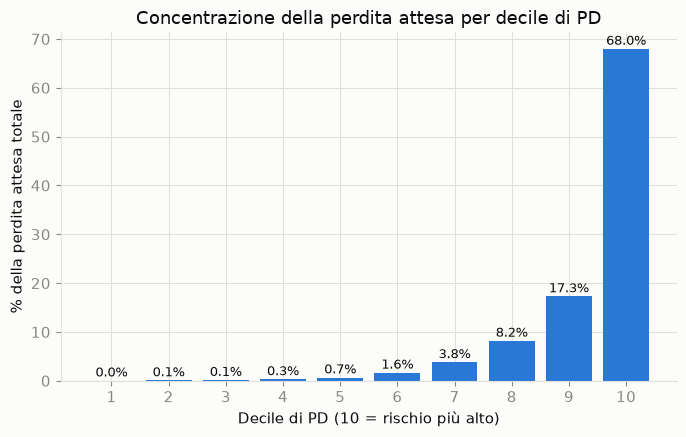

In [8]:
fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(decile_summary.index.astype(str), decile_summary['pct_EL_totale'], color=COLOR_SEQ)
ax.set_xlabel('Decile di PD (10 = rischio più alto)')
ax.set_ylabel('% della perdita attesa totale')
ax.set_title('Concentrazione della perdita attesa per decile di PD')
for bar, val in zip(bars, decile_summary['pct_EL_totale']):
    ax.annotate(f'{val:.1f}%', xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
                xytext=(0, 3), textcoords='offset points', ha='center', fontsize=9, color=TEXT_COLOR)
plt.tight_layout()
plt.show()

In [9]:
top1 = decile_summary['pct_EL_totale'].iloc[-1]
top2 = decile_summary['pct_EL_totale'].iloc[-2:].sum()
top3 = decile_summary['pct_EL_totale'].iloc[-3:].sum()
print(f"Quota di EL totale nel decile più rischioso:     {top1:.1f}%")
print(f"Quota di EL totale nei 2 decili più rischiosi:    {top2:.1f}%")
print(f"Quota di EL totale nei 3 decili più rischiosi:    {top3:.1f}%")

Quota di EL totale nel decile più rischioso:     68.0%
Quota di EL totale nei 2 decili più rischiosi:    85.2%
Quota di EL totale nei 3 decili più rischiosi:    93.4%


**La distribuzione è, come atteso, molto concentrata.** Il solo decile più rischioso (15.000
clienti, il 10% del portafoglio) genera da solo circa **il 68% dell'intera perdita attesa**; i primi
due decili insieme arrivano a circa l'**85%**. Il tasso di default osservato cresce in modo
monotono da decile a decile (buon segno: conferma che la PD stimata ordina correttamente il
rischio reale, non solo sulla carta) — ma è proprio questa concentrazione a rendere il rischio di
credito un problema gestibile: intervenire con attenzione extra su una minoranza di clienti ad alto
rischio intercetta la maggior parte della perdita attesa complessiva, molto più efficacemente che
un controllo uniforme su tutto il portafoglio.

### Confronto con una soglia di approvazione

Se rifiutassimo tutti i clienti con PD sopra una certa soglia, quanta perdita attesa eviteremmo, e
quanti clienti "buoni" (che non sarebbero andati in default) rifiuteremmo per errore?

In [10]:
total_el = data['EL'].sum()
thresholds = [0.0668, 0.10, 0.20, 0.30, 0.50]  # 0.0668 = tasso di default osservato (soglia "naturale")

rows = []
for thr in thresholds:
    rejected = data[data['PD'] >= thr]
    el_avoided = rejected['EL'].sum()
    good_lost = (rejected['SeriousDlqin2yrs'] == 0).sum()   # falsi positivi: clienti buoni rifiutati per errore
    bad_avoided = (rejected['SeriousDlqin2yrs'] == 1).sum()  # veri positivi: insolventi correttamente evitati
    rows.append({
        'soglia_PD': thr,
        'clienti_rifiutati': len(rejected),
        '%_portafoglio_rifiutato': len(rejected) / len(data) * 100,
        'EL_evitata': el_avoided,
        '%_EL_evitata': el_avoided / total_el * 100,
        'clienti_buoni_persi': good_lost,
        'clienti_a_rischio_evitati': bad_avoided,
        'buoni_persi_per_ogni_rischio_evitato': good_lost / bad_avoided,
    })

threshold_table = pd.DataFrame(rows)
threshold_table.round(2)

,soglia_PD,clienti_rifiutati,%_portafoglio_rifiutato,EL_evitata,%_EL_evitata,clienti_buoni_persi,clienti_a_rischio_evitati,buoni_persi_per_ogni_rischio_evitato
0,0.07,35995,24.00,84837936.95,89.23,27950,8045,3.47
1,0.10,24777,16.52,76647805.93,80.62,17662,7115,2.48
2,0.20,12933,8.62,60903249.67,64.06,7525,5408,1.39
3,0.30,8459,5.64,49573684.92,52.14,4202,4257,0.99
4,0.50,3439,2.29,27106009.29,28.51,1177,2262,0.52


**Non esiste una soglia "corretta" in astratto**: la scelta dipende dal margine di profitto atteso
su un cliente buono rispetto alla perdita su uno che va in default, dati che questo dataset non
fornisce. Il pattern però è chiaro e utile di per sé: a soglie basse (es. il tasso di default
osservato, 6,68%) si evita l'89% della perdita attesa totale, ma si perdono quasi **3,5 clienti
buoni per ogni cliente a rischio effettivamente evitato**; a soglie più alte (es. 0,30) il rapporto
si riequilibra fino a circa 1:1. Nessuna soglia elimina il compromesso — lo sposta soltanto.

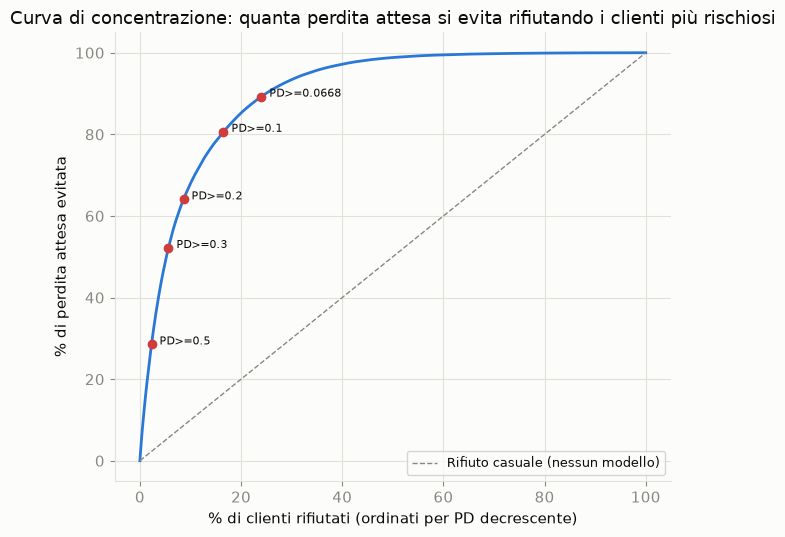

In [11]:
data_sorted = data.sort_values('PD', ascending=False).reset_index()
data_sorted['pct_clienti_rifiutati'] = (np.arange(1, len(data_sorted) + 1)) / len(data_sorted) * 100
data_sorted['pct_EL_cumulata'] = data_sorted['EL'].cumsum() / data_sorted['EL'].sum() * 100

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.plot(data_sorted['pct_clienti_rifiutati'], data_sorted['pct_EL_cumulata'], color=COLOR_SEQ, linewidth=2)
ax.plot([0, 100], [0, 100], color=MUTED_COLOR, linestyle='--', linewidth=1, label='Rifiuto casuale (nessun modello)')

for thr in thresholds:
    row = threshold_table[threshold_table['soglia_PD'] == thr].iloc[0]
    ax.scatter(row['%_portafoglio_rifiutato'], row['%_EL_evitata'], color=COLOR_CRITICAL, zorder=5)
    ax.annotate(f"  PD>={thr}", (row['%_portafoglio_rifiutato'], row['%_EL_evitata']), fontsize=8, color=TEXT_COLOR)

ax.set_xlabel('% di clienti rifiutati (ordinati per PD decrescente)')
ax.set_ylabel('% di perdita attesa evitata')
ax.set_title('Curva di concentrazione: quanta perdita attesa si evita rifiutando i clienti più rischiosi')
ax.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()

## 5. Salvataggio dei risultati per cliente

In [12]:
output = data.reset_index()[['id', 'PD', 'EAD', 'EL']].rename(columns={'id': 'CustomerID'})
output['EAD'] = output['EAD'].round(2)
output['EL'] = output['EL'].round(2)

OUTPUT_PATH = PROJECT_ROOT / 'data' / 'processed' / 'expected_loss_per_cliente.csv'
output.to_csv(OUTPUT_PATH, index=False)

print(f"Salvato: {OUTPUT_PATH.relative_to(PROJECT_ROOT).as_posix()}  ({len(output):,} righe)")

Salvato: data/processed/expected_loss_per_cliente.csv  (149,999 righe)


## 6. Limiti di questa analisi

Questo notebook applica correttamente il **framework** PD/LGD/EAD usato nella pratica bancaria per
quantificare il rischio di credito, ed è utile per dimostrarne la comprensione — ma i **valori
assoluti** prodotti (perdita attesa totale, per cliente, per decile) non vanno letti come una stima
accurata di un vero portafoglio, per motivi dichiarati fin dall'inizio, qui riassunti insieme:

- **EAD è un proxy, non un dato osservato**: assume lo stesso limite di fido (25.000 $) per tutti i
  clienti, mentre nella realtà varia per cliente in base a reddito, storia creditizia e politiche
  della banca. Il dataset non contiene l'informazione necessaria per fare di meglio.
- **LGD è un parametro esterno preso dalla letteratura di settore (55%, con range 40-70% testato),
  non calcolato su dati di recupero effettivi** — in un contesto operativo reale andrebbe stimato
  dallo storico dei recuperi post-default della banca, tipicamente segmentato per tipo di prodotto,
  garanzie e anno di osservazione, non un singolo valore uguale per l'intero portafoglio.
- **La PD stessa** deriva da un modello allenato su dati storici di un periodo e una popolazione
  specifici (il dataset Kaggle *Give Me Some Credit*): un utilizzo in produzione richiederebbe
  monitoraggio continuo e ricalibrazione periodica, non un solo addestramento una tantum.
- **Nessuna correlazione tra i default è modellata**: l'Expected Loss qui è semplicemente la somma
  delle perdite attese individuali, un'approssimazione ragionevole per la perdita *media* attesa ma
  che non cattura il rischio di perdite eccezionalmente alte in scenari di stress macroeconomico
  (dove i default tendono a essere correlati tra loro, non indipendenti).

In sintesi: il metodo è quello giusto, i numeri sono illustrativi. Un utilizzo reale richiederebbe
sostituire ciascuna assunzione dichiarata qui con una stima calibrata sui dati storici della banca.